# NILM Approach 3 — Heterogeneous Appliance-Specific Specialist Models + Stacking Meta-Model

**Appliances:** Laptop, Washing Machine, TV, Fridge, Microwave
**Window:** 100 samples (~10 min) | **Stride:** 20 samples (~2 min)
**Label rule:** state at the CENTER sample of each window (not majority/any)
**Split:** Train / Meta / Test = 70% / 15% / 15% (day-cycled, no leakage)

**Specialists** (each predicts ONLY its own appliance, from raw aggregate window + 13-D
knowledge vector, no cross-appliance information):
- Laptop: CNN + BiLSTM
- Washing Machine: CNN + BiLSTM
- TV: CNN + Transformer (self-attention) block
- Fridge: GRU
- Microwave: CNN + BiLSTM

Each specialist outputs a **128-D learned feature** and a **scalar probability**. On the
**Meta split**, all 5 specialists run in inference mode (never trained further here) to
produce a 645-D meta-feature vector (5x128 + 5 probabilities), which trains a small
stacking meta-model (645 -> 256 -> 128 -> 5) for 10 epochs, batch size 128. Final
evaluation runs the same specialist -> meta pipeline on the held-out Test split.

**Assumptions made (not specified in the brief) -- verify against your intended design:**
- Real mains channel used as aggregate (not a synthetic sum).
- 13 knowledge features = the project's pruned 12 + `max_power` (13th).
- ON-power thresholds: laptop 15W, washing machine 20W, TV 50W, fridge 20W, microwave 600W.
- Specialists trained for up to 30 epochs with early stopping; the 10-epoch/batch-128
  setting is applied to the meta-model only, as specified.


## 1. Install & Imports

In [ ]:
!pip install -q tensorflow scikit-learn scipy pandas numpy matplotlib

In [ ]:
import os, json, pickle, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from scipy.stats import skew, kurtosis as kurtosis_fn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                              accuracy_score, classification_report)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

RANDOM_SEED = 42
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Mount Drive & Configuration

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

CONFIG = {
    "house_dir": "/content/drive/MyDrive/SEM7PROJ/house_1",
    "checkpoint_dir": "/content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous",
    "sample_period": "6s",
    "sample_seconds": 6,
    "window_size": 100,     # ~10 minutes at 6s
    "window_stride": 20,    # ~2 minutes at 6s
    "median_kernel": 5,
    "appliances": ["laptop", "washing machine", "tv", "fridge", "microwave"],
    "on_thresholds": {"laptop": 15, "washing machine": 20, "tv": 50, "fridge": 20, "microwave": 600},
    "specialist_batch_size": 64,
    "specialist_epochs": 30,
    "meta_epochs": 10,
    "meta_batch_size": 128,
    "meta_feature_dim": 128,
}
os.makedirs(CONFIG["checkpoint_dir"], exist_ok=True)
print("Config ready.")

Mounted at /content/drive
Config ready.


## 3. Memory-Efficient Dataset Loading (one channel at a time, float32)
Same approach used to fix the earlier Colab RAM crash -- never holds more than one raw
channel in memory simultaneously.

In [ ]:
def print_memory(label=""):
    try:
        import psutil
        mem_gb = psutil.Process().memory_info().rss / (1024**3)
        print(f"[RAM] {label}: {mem_gb:.2f} GB")
    except ImportError:
        pass

def load_labels(house_dir):
    labels = {}
    with open(os.path.join(house_dir, "labels.dat"), "r") as f:
        for line in f:
            parts = line.strip().split(" ", 1)
            if len(parts) == 2:
                ch_num, name = parts
                labels[int(ch_num)] = name.strip().lower().replace("_", " ")
    return labels

def find_channel_path(house_dir, channel_num):
    path_dat = os.path.join(house_dir, f"channel_{channel_num}.dat")
    path_csv = os.path.join(house_dir, f"channel_{channel_num}.csv")
    if os.path.exists(path_dat):
        return path_dat
    if os.path.exists(path_csv):
        return path_csv
    raise FileNotFoundError(f"No data file for channel {channel_num}")

def get_first_timestamp(house_dir, channel_num):
    path = find_channel_path(house_dir, channel_num)
    with open(path, "r") as f:
        first_line = f.readline()
    sep = " " if path.endswith(".dat") else ","
    ts = int(first_line.strip().split(sep)[0])
    return pd.to_datetime(ts, unit="s")

def load_and_resample_channel(house_dir, channel_num, period, origin):
    path = find_channel_path(house_dir, channel_num)
    sep = " " if path.endswith(".dat") else ","
    raw = pd.read_csv(path, sep=sep, header=None, names=["timestamp", "power"],
                       dtype={"timestamp": "int64", "power": "float32"})
    raw["timestamp"] = pd.to_datetime(raw["timestamp"], unit="s")
    raw = raw.set_index("timestamp").sort_index()
    resampled = raw["power"].resample(period, origin=origin).mean().astype("float32")
    del raw
    gc.collect()
    return resampled

labels_map = load_labels(CONFIG["house_dir"])
print(f"Found {len(labels_map)} channels.")

# Explicit channel map -- verified against this house's labels.dat.
MANUAL_CHANNEL_MAP = {"laptop": 4, "washing machine": 5, "tv": 7, "fridge": 12, "microwave": 13}

def find_channel_for_appliance(labels_map, appliance_name, manual_map=MANUAL_CHANNEL_MAP):
    if appliance_name in manual_map:
        ch = manual_map[appliance_name]
        if ch not in labels_map:
            raise ValueError(f"Manually mapped channel {ch} for '{appliance_name}' not found.")
        return ch
    words = appliance_name.lower().split()
    candidates = [ch for ch, name in labels_map.items() if all(w in name for w in words)]
    if not candidates:
        raise ValueError(f"No channel found for '{appliance_name}'")
    return candidates[0]

mains_channel = find_channel_for_appliance(labels_map, "aggregate")
all_channels = {"aggregate": mains_channel}
for app in CONFIG["appliances"]:
    all_channels[app] = find_channel_for_appliance(labels_map, app)

shared_origin = min(get_first_timestamp(CONFIG["house_dir"], ch) for ch in all_channels.values())
print("Shared resample origin:", shared_origin)

resampled_data = {}
for name, ch in all_channels.items():
    resampled_data[name] = load_and_resample_channel(CONFIG["house_dir"], ch, CONFIG["sample_period"], shared_origin)
    print(f"{name:20s} -> channel {ch} ({labels_map[ch]}) | length: {len(resampled_data[name])}")
    print_memory(f"after {name}")

Found 53 channels.
Shared resample origin: 2012-11-09 22:28:15
aggregate            -> channel 1 (aggregate) | length: 23454645
[RAM] after aggregate: 1.14 GB
laptop               -> channel 4 (laptop) | length: 23360459
[RAM] after laptop: 1.40 GB
washing machine      -> channel 5 (washing machine) | length: 23454672
[RAM] after washing machine: 1.67 GB
tv                   -> channel 7 (tv) | length: 23454675
[RAM] after tv: 1.94 GB
fridge               -> channel 12 (fridge) | length: 22950715
[RAM] after fridge: 2.19 GB
microwave            -> channel 13 (microwave) | length: 22950716
[RAM] after microwave: 2.45 GB


## 4. Assemble & Preprocess

In [ ]:
filtered = pd.DataFrame(resampled_data)
del resampled_data
gc.collect()

max_ffill = int(60 / CONFIG["sample_seconds"])
filtered = filtered.ffill(limit=max_ffill)
filtered = filtered.dropna(subset=CONFIG["appliances"] + ["aggregate"])
gc.collect()

def median_filter_values(values, kernel_size):
    if kernel_size % 2 == 0:
        kernel_size += 1
    return medfilt(values, kernel_size=kernel_size).astype(np.float32)

for col in CONFIG["appliances"] + ["aggregate"]:
    filtered[col] = median_filter_values(filtered[col].values.astype(np.float32), CONFIG["median_kernel"])
filtered[filtered < 0] = 0
gc.collect()
print("Preprocessing complete. Rows:", len(filtered))

Preprocessing complete. Rows: 4834877


## 5. ON/OFF Labels & Train / Meta / Test Day-Cycled Split (70/15/15)

In [ ]:
for app in CONFIG["appliances"]:
    filtered[f"{app}_on"] = (filtered[app] > CONFIG["on_thresholds"][app])

filtered["date"] = filtered.index.normalize()
unique_days = filtered["date"].drop_duplicates().sort_values().reset_index(drop=True)

# 20-bucket cycle: 14/20=70% train, 3/20=15% meta, 3/20=15% test
def assign_split(i):
    r = i % 20
    if r < 14:
        return "train"
    elif r < 17:
        return "meta"
    else:
        return "test"

day_split = [assign_split(i) for i in range(len(unique_days))]
day_assignment = pd.Series(day_split, index=unique_days)
filtered["split"] = filtered["date"].map(day_assignment)

train_df = filtered[filtered["split"] == "train"].drop(columns=["date", "split"]).copy()
meta_df = filtered[filtered["split"] == "meta"].drop(columns=["date", "split"]).copy()
test_df = filtered[filtered["split"] == "test"].drop(columns=["date", "split"]).copy()
del filtered
gc.collect()

print(f"Rows -> train: {len(train_df)} | meta: {len(meta_df)} | test: {len(test_df)}")
print("\nAppliance ON-event coverage per split:")
for app in CONFIG["appliances"]:
    counts = {s: int(d[f"{app}_on"].sum()) for s, d in [("train", train_df), ("meta", meta_df), ("test", test_df)]}
    flag = " <-- ZERO EVENTS" if 0 in counts.values() else ""
    print(f"  {app:20s} {counts}{flag}")

Rows -> train: 3459580 | meta: 691552 | test: 683745

Appliance ON-event coverage per split:
  laptop               {'train': 1576694, 'meta': 352550, 'test': 294513}
  washing machine      {'train': 231184, 'meta': 47249, 'test': 44971}
  tv                   {'train': 458259, 'meta': 115550, 'test': 87529}
  fridge               {'train': 1505832, 'meta': 301868, 'test': 300209}
  microwave            {'train': 18857, 'meta': 4314, 'test': 3414}


## 6. 13-D Window Knowledge Vector
Computed purely from the aggregate signal (leakage-safe by construction).

In [ ]:
KNOWLEDGE_FEATURE_NAMES = [
    "mean_power", "std_power", "min_power", "max_power", "power_jump", "num_transitions",
    "rise_time", "duty_cycle", "iqr_power", "autocorr_peak_strength", "skewness", "kurtosis", "dominant_period",
]
N_KNOWLEDGE_FEATURES = len(KNOWLEDGE_FEATURE_NAMES)
assert N_KNOWLEDGE_FEATURES == 13

def compute_window_knowledge(window_agg, sample_seconds=6, edge_threshold_frac=0.1):
    w = window_agg.astype(np.float64)
    n = len(w)
    mean_power, min_power, max_power = float(np.mean(w)), float(np.min(w)), float(np.max(w))
    std_power = float(np.std(w))
    range_power = max_power - min_power
    q75, q25 = np.percentile(w, [75, 25])
    iqr_power = float(q75 - q25)

    diffs = np.diff(w) if n > 1 else np.array([0.0])
    power_jump = float(np.max(np.abs(diffs)))
    edge_thresh = max(edge_threshold_frac * range_power, 5.0)
    num_transitions = int(np.sum(np.abs(diffs) > edge_thresh)) if n > 1 else 0

    if n > 4 and std_power > 1e-6:
        w_centered = w - mean_power
        acf = np.correlate(w_centered, w_centered, mode="full")[n - 1:]
        acf = acf / (acf[0] + 1e-8)
        search_start = max(2, n // 20)
        if search_start < len(acf) - 1:
            peak_lag = int(np.argmax(acf[search_start:])) + search_start
            dominant_period = float(peak_lag * sample_seconds)
            autocorr_peak_strength = float(acf[peak_lag])
        else:
            dominant_period, autocorr_peak_strength = 0.0, 0.0
    else:
        dominant_period, autocorr_peak_strength = 0.0, 0.0

    peak_idx = int(np.argmax(w))
    rise_time = float(peak_idx * sample_seconds)
    duty_thresh = min_power + 0.5 * range_power
    duty_cycle = float(np.mean(w > duty_thresh)) if range_power > 0 else 0.0
    skewness, kurt = (float(skew(w)), float(kurtosis_fn(w))) if std_power > 1e-6 else (0.0, 0.0)

    return [mean_power, std_power, min_power, max_power, power_jump, num_transitions,
            rise_time, duty_cycle, iqr_power, autocorr_peak_strength, skewness, kurt, dominant_period]

print("13 knowledge features:", KNOWLEDGE_FEATURE_NAMES)

13 knowledge features: ['mean_power', 'std_power', 'min_power', 'max_power', 'power_jump', 'num_transitions', 'rise_time', 'duty_cycle', 'iqr_power', 'autocorr_peak_strength', 'skewness', 'kurtosis', 'dominant_period']


## 7. Sliding Windows -- Center-Point Labeling
Label for each appliance is its ON/OFF state at the CENTER sample of the window
(index `window_size // 2`), not majority-vote or any-occurrence.

In [ ]:
def build_windows_center(df, window_size, stride, appliances):
    agg = df["aggregate"].values
    n_samples = len(agg)
    center_offset = window_size // 2
    X_seq, X_know, Y_all = [], [], []
    for start in range(0, n_samples - window_size + 1, stride):
        end = start + window_size
        window_agg = agg[start:end]
        if np.isnan(window_agg).any():
            continue
        center_idx = start + center_offset
        labels = [int(df[f"{app}_on"].values[center_idx]) for app in appliances]
        X_seq.append(window_agg)
        X_know.append(compute_window_knowledge(window_agg))
        Y_all.append(labels)
    return (np.array(X_seq, dtype=np.float32), np.array(X_know, dtype=np.float32), np.array(Y_all))

WS, ST = CONFIG["window_size"], CONFIG["window_stride"]
X_train_seq, X_train_know, Y_train_all = build_windows_center(train_df, WS, ST, CONFIG["appliances"])
X_meta_seq, X_meta_know, Y_meta_all = build_windows_center(meta_df, WS, ST, CONFIG["appliances"])
X_test_seq, X_test_know, Y_test_all = build_windows_center(test_df, WS, ST, CONFIG["appliances"])

print("Train:", X_train_seq.shape, "| Meta:", X_meta_seq.shape, "| Test:", X_test_seq.shape)
for i, app in enumerate(CONFIG["appliances"]):
    print(f"  {app:20s} positive rate -> train: {Y_train_all[:,i].mean():.4f} | meta: {Y_meta_all[:,i].mean():.4f} | test: {Y_test_all[:,i].mean():.4f}")

Train: (172975, 100) | Meta: (34573, 100) | Test: (34183, 100)
  laptop               positive rate -> train: 0.4556 | meta: 0.5098 | test: 0.4316
  washing machine      positive rate -> train: 0.0665 | meta: 0.0686 | test: 0.0661
  tv                   positive rate -> train: 0.1323 | meta: 0.1671 | test: 0.1280
  fridge               positive rate -> train: 0.4353 | meta: 0.4366 | test: 0.4387
  microwave            positive rate -> train: 0.0054 | meta: 0.0065 | test: 0.0049


## 8. Scaling (fit on TRAIN only)

In [ ]:
seq_scaler = MinMaxScaler()
X_train_seq_s = seq_scaler.fit_transform(X_train_seq.reshape(-1, 1)).reshape(X_train_seq.shape)[..., np.newaxis]
X_meta_seq_s = seq_scaler.transform(X_meta_seq.reshape(-1, 1)).reshape(X_meta_seq.shape)[..., np.newaxis]
X_test_seq_s = seq_scaler.transform(X_test_seq.reshape(-1, 1)).reshape(X_test_seq.shape)[..., np.newaxis]

know_scaler = MinMaxScaler()
X_train_know_s = know_scaler.fit_transform(X_train_know)
X_meta_know_s = know_scaler.transform(X_meta_know)
X_test_know_s = know_scaler.transform(X_test_know)

with open(os.path.join(CONFIG["checkpoint_dir"], "scalers.pkl"), "wb") as f:
    pickle.dump({"seq_scaler": seq_scaler, "know_scaler": know_scaler,
                 "knowledge_feature_names": KNOWLEDGE_FEATURE_NAMES, "config": CONFIG}, f)
print("Scaling complete.")

Scaling complete.


## 9. Specialist Architectures
Each specialist takes `[aggregate_sequence, knowledge_vector]` and outputs
`(feature_128, probability)`. Architectures differ by appliance as specified.

In [ ]:
def transformer_block(x, num_heads=4, key_dim=16, ff_dim=64, dropout=0.1):
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim)(x, x)
    attn_out = layers.Dropout(dropout)(attn_out)
    x = layers.LayerNormalization(epsilon=1e-6)(x + attn_out)
    ff = layers.Dense(ff_dim, activation="relu")(x)
    ff = layers.Dense(x.shape[-1])(ff)
    ff = layers.Dropout(dropout)(ff)
    return layers.LayerNormalization(epsilon=1e-6)(x + ff)

def cnn_frontend(seq_input):
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(seq_input)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    return x

def knowledge_branch(know_input):
    k = layers.Dense(32, activation="relu")(know_input)
    k = layers.Dense(16, activation="relu")(k)
    return k

def finish_specialist(seq_input, know_input, backbone_out, name, feature_dim=128):
    know_encoded = knowledge_branch(know_input)

    fused = layers.Concatenate()([backbone_out, know_encoded])

    shared = layers.Dense(64, activation="relu")(fused)
    shared = layers.Dropout(0.3)(shared)

    feature_128 = layers.Dense(
        feature_dim,
        activation="relu",
        name=f"{name}_feature128"
    )(shared)

    prob = layers.Dense(
        1,
        activation="sigmoid",
        name=f"{name}_probability"
    )(feature_128)

    model = models.Model(
        inputs=[seq_input, know_input],
        outputs=[feature_128, prob],
        name=f"specialist_{name}"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=5e-4,
            clipnorm=1.0
        ),
        loss=[
            None,
            "binary_crossentropy"
        ],
        metrics=[
            [],
            [
                tf.keras.metrics.BinaryAccuracy(name="acc"),
                tf.keras.metrics.Precision(name="precision"),
                tf.keras.metrics.Recall(name="recall")
            ]
        ]
    )

    return model

def build_specialist_cnn_bilstm(window_size, n_knowledge, name, feature_dim=128):
    seq_input = layers.Input(shape=(window_size, 1), name=f"{name}_sequence")
    know_input = layers.Input(shape=(n_knowledge,), name=f"{name}_knowledge")
    x = cnn_frontend(seq_input)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=False))(x)
    return finish_specialist(seq_input, know_input, x, name, feature_dim)

def build_specialist_cnn_transformer(window_size, n_knowledge, name, feature_dim=128):
    seq_input = layers.Input(shape=(window_size, 1), name=f"{name}_sequence")
    know_input = layers.Input(shape=(n_knowledge,), name=f"{name}_knowledge")
    x = cnn_frontend(seq_input)
    x = layers.Dense(64)(x)  # project to a fixed dim for the transformer block
    x = transformer_block(x, num_heads=4, key_dim=16, ff_dim=64)
    x = layers.GlobalAveragePooling1D()(x)
    return finish_specialist(seq_input, know_input, x, name, feature_dim)

def build_specialist_gru(window_size, n_knowledge, name, feature_dim=128):
    seq_input = layers.Input(shape=(window_size, 1), name=f"{name}_sequence")
    know_input = layers.Input(shape=(n_knowledge,), name=f"{name}_knowledge")
    x = layers.GRU(64, return_sequences=False)(seq_input)   # no CNN front-end for this specialist
    return finish_specialist(seq_input, know_input, x, name, feature_dim)

SPECIALIST_BUILDERS = {
    "laptop": build_specialist_cnn_bilstm,
    "washing machine": build_specialist_cnn_bilstm,
    "tv": build_specialist_cnn_transformer,
    "fridge": build_specialist_gru,
    "microwave": build_specialist_cnn_bilstm,
}
print("Specialist architecture map:", {k: v.__name__ for k, v in SPECIALIST_BUILDERS.items()})

Specialist architecture map: {'laptop': 'build_specialist_cnn_bilstm', 'washing machine': 'build_specialist_cnn_bilstm', 'tv': 'build_specialist_cnn_transformer', 'fridge': 'build_specialist_gru', 'microwave': 'build_specialist_cnn_bilstm'}


## 10. Train Each Specialist Independently (Train split only)

In [ ]:
specialist_models = {}
specialist_histories = {}

for i, app in enumerate(CONFIG["appliances"]):
    print(f"\n{'='*60}\nTraining specialist: {app}\n{'='*60}")
    safe_name = app.replace(" ", "_")
    ckpt_path = os.path.join(CONFIG["checkpoint_dir"], f"specialist_{safe_name}_best.keras")

    if os.path.exists(ckpt_path):
        print(f"Existing checkpoint found for {app} -- loading instead of retraining.")
        model = tf.keras.models.load_model(ckpt_path)
    else:
        builder = SPECIALIST_BUILDERS[app]
        model = builder(CONFIG["window_size"], N_KNOWLEDGE_FEATURES, safe_name)

        y_train_i = Y_train_all[:, i].astype(np.float32)
        y_meta_i = Y_meta_all[:, i].astype(np.float32)  # used only as val monitor, never trained on

        pos = y_train_i.sum()
        neg = len(y_train_i) - pos
        class_weight = {0: 1.0, 1: float(np.clip(neg / max(pos, 1), 1.0, 15.0))}

        cb = [
            callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True, verbose=0),
            callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
        ]
        history = model.fit(
    [X_train_seq_s, X_train_know_s],

    [
        np.zeros((len(y_train_i), 128), dtype=np.float32),
        y_train_i
    ],

    validation_data=(
        [X_meta_seq_s, X_meta_know_s],
        [
            np.zeros((len(y_meta_i), 128), dtype=np.float32),
            y_meta_i
        ]
    ),

    epochs=CONFIG["specialist_epochs"],
    batch_size=CONFIG["specialist_batch_size"],
    callbacks=cb,
    verbose=1
)
        specialist_histories[app] = history.history

    specialist_models[app] = model
    print(f"Specialist for {app} ready.")

print("\nAll 5 specialists trained/loaded.")
print("NOTE: Keras class_weight with a named single output can be finicky across versions;")
print("if training collapses to all-negative predictions for a rare appliance, apply")
print("sample_weight computed from class_weight instead, or oversample positives.")


Training specialist: laptop
Existing checkpoint found for laptop -- loading instead of retraining.
Specialist for laptop ready.

Training specialist: washing machine
Existing checkpoint found for washing machine -- loading instead of retraining.
Specialist for washing machine ready.

Training specialist: tv
Existing checkpoint found for tv -- loading instead of retraining.
Specialist for tv ready.

Training specialist: fridge
Existing checkpoint found for fridge -- loading instead of retraining.
Specialist for fridge ready.

Training specialist: microwave
Existing checkpoint found for microwave -- loading instead of retraining.
Specialist for microwave ready.

All 5 specialists trained/loaded.
NOTE: Keras class_weight with a named single output can be finicky across versions;
if training collapses to all-negative predictions for a rare appliance, apply
sample_weight computed from class_weight instead, or oversample positives.


## 11. Generate Meta-Features (645-D) on the Meta Split
Every specialist runs in pure inference mode here -- none are updated further. This is the
standard stacking-ensemble protocol: specialists never see Meta during their own training,
so the meta-model learns on genuinely held-out specialist outputs.

In [ ]:
def generate_meta_features(seq_data, know_data, specialist_models, appliances):
    feature_blocks = []
    prob_blocks = []
    for app in appliances:
        safe_name = app.replace(" ", "_")
        model = specialist_models[app]
        feat, prob = model.predict([seq_data, know_data], verbose=0)
        feature_blocks.append(feat)     # (n, 128)
        prob_blocks.append(prob)        # (n, 1)
    all_features = np.concatenate(feature_blocks, axis=1)   # (n, 640)
    all_probs = np.concatenate(prob_blocks, axis=1)         # (n, 5)
    meta_input = np.concatenate([all_features, all_probs], axis=1)  # (n, 645)
    return meta_input, all_probs

X_meta_input, meta_specialist_probs = generate_meta_features(X_meta_seq_s, X_meta_know_s, specialist_models, CONFIG["appliances"])
X_test_input, test_specialist_probs = generate_meta_features(X_test_seq_s, X_test_know_s, specialist_models, CONFIG["appliances"])

print("Meta input shape:", X_meta_input.shape, "(expected: (n, 645))")
print("Test input shape:", X_test_input.shape)
assert X_meta_input.shape[1] == 5 * CONFIG["meta_feature_dim"] + 5 == 645

Meta input shape: (34573, 645) (expected: (n, 645))
Test input shape: (34183, 645)


## 12. Meta Model (645 -> 256 -> 128 -> 5), 10 Epochs, Batch Size 128

In [ ]:
def build_meta_model(input_dim, n_appliances):
    meta_input = layers.Input(shape=(input_dim,), name="meta_features")
    x = layers.Dense(256, activation="relu")(meta_input)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    output = layers.Dense(n_appliances, activation="sigmoid", name="meta_state")(x)
    model = models.Model(inputs=meta_input, outputs=output, name="meta_model")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="acc"),
                 tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall")]
    )
    return model

meta_model = build_meta_model(645, len(CONFIG["appliances"]))
meta_model.summary()

meta_ckpt_path = os.path.join(CONFIG["checkpoint_dir"], "meta_model_best.keras")
meta_cb = [
    callbacks.ModelCheckpoint(meta_ckpt_path, monitor="loss", save_best_only=True, verbose=1),
]

# Meta model trains ON the meta split's generated features -- a portion is held out
# internally (validation_split) purely to watch for overfitting during these 10 epochs.
meta_history = meta_model.fit(
    X_meta_input, Y_meta_all.astype(np.float32),
    validation_split=0.15,
    epochs=CONFIG["meta_epochs"], batch_size=CONFIG["meta_batch_size"],
    callbacks=meta_cb, verbose=1
)

Model: "meta_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ meta_features (InputLayer)      │ (None, 645)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       165,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ meta_state (Dense)              │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 198,917 (777.02 KB)

 Trainable params: 198,917 (777.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - acc: 0.8132 - loss: 0.3600 - precision: 0.6160 - recall: 0.6382
Epoch 1: loss improved from None to 0.31280, saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous/meta_model_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous/meta_model_best.keras
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - acc: 0.8392 - loss: 0.3128 - precision: 0.6632 - recall: 0.6809 - val_acc: 0.8050 - val_loss: 0.3585 - val_precision: 0.5324 - val_recall: 0.7500
Epoch 2/10
223/230 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.8554 - loss: 0.2849 - precision: 0.6943 - recall: 0.7226
Epoch 2: loss improved from 0.31280 to 0.28379, saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous/meta_model_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous/meta_model_best.keras
230/230 ━━━━━━━━━━

## 13. Plot Meta-Model Training Curves

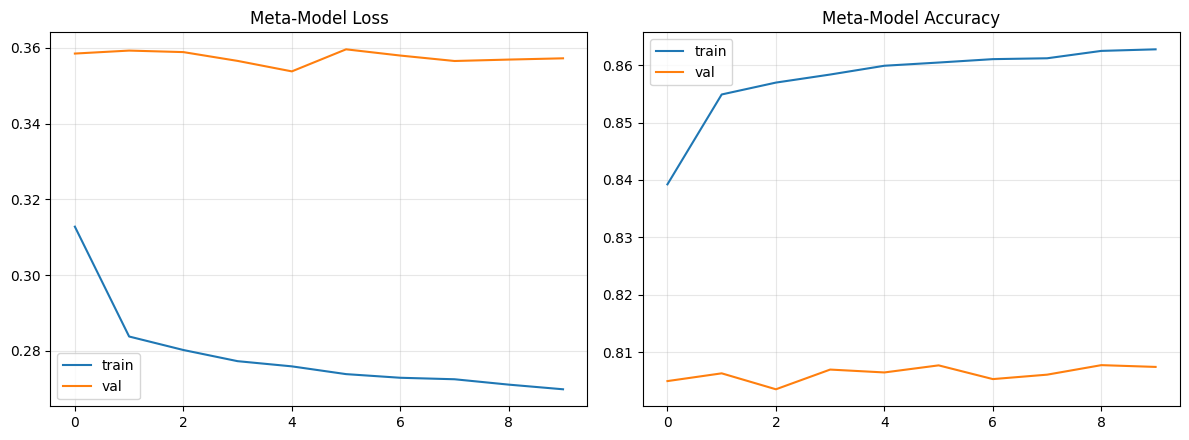

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(meta_history.history["loss"], label="train")
axes[0].plot(meta_history.history["val_loss"], label="val")
axes[0].set_title("Meta-Model Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(meta_history.history["acc"], label="train")
axes[1].plot(meta_history.history["val_acc"], label="val")
axes[1].set_title("Meta-Model Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["checkpoint_dir"], "meta_training_curves.png"), dpi=150)
plt.show()

## 14. Final Evaluation on Test Split (specialists -> meta-features -> meta-model)

In [ ]:
test_meta_pred_prob = meta_model.predict(X_test_input, verbose=0)
test_meta_pred = (test_meta_pred_prob > 0.5).astype(int)

print(classification_report(Y_test_all, test_meta_pred, target_names=CONFIG["appliances"], zero_division=0))

results = []
for i, app in enumerate(CONFIG["appliances"]):
    acc = accuracy_score(Y_test_all[:, i], test_meta_pred[:, i])
    p = precision_score(Y_test_all[:, i], test_meta_pred[:, i], zero_division=0)
    r = recall_score(Y_test_all[:, i], test_meta_pred[:, i], zero_division=0)
    f1 = f1_score(Y_test_all[:, i], test_meta_pred[:, i], zero_division=0)
    # also report the specialist's own standalone probability accuracy, for comparison
    specialist_pred_i = (test_specialist_probs[:, i] > 0.5).astype(int)
    specialist_f1 = f1_score(Y_test_all[:, i], specialist_pred_i, zero_division=0)
    results.append({"appliance": app, "accuracy": acc, "precision": p, "recall": r,
                     "f1_meta": f1, "f1_specialist_alone": specialist_f1})
    print(f"  {app:20s} | Acc: {acc:.3f} | P: {p:.3f} | R: {r:.3f} | F1(meta): {f1:.3f} | F1(specialist alone): {specialist_f1:.3f}")

results_df = pd.DataFrame(results)
print("\n=== Average across 5 appliances ===")
print(results_df.drop(columns="appliance").mean().round(4))

                 precision    recall  f1-score   support

         laptop       0.59      0.82      0.69     14753
washing machine       0.84      0.76      0.80      2259
             tv       0.54      0.73      0.62      4374
         fridge       0.69      0.68      0.68     14996
      microwave       0.75      0.54      0.63       169

      micro avg       0.63      0.75      0.68     36551
      macro avg       0.68      0.71      0.68     36551
   weighted avg       0.64      0.75      0.68     36551
    samples avg       0.47      0.53      0.48     36551

  laptop               | Acc: 0.680 | P: 0.593 | R: 0.817 | F1(meta): 0.688 | F1(specialist alone): 0.661
  washing machine      | Acc: 0.974 | P: 0.836 | R: 0.762 | F1(meta): 0.797 | F1(specialist alone): 0.788
  tv                   | Acc: 0.886 | P: 0.539 | R: 0.734 | F1(meta): 0.622 | F1(specialist alone): 0.569
  fridge               | Acc: 0.723 | P: 0.685 | R: 0.681 | F1(meta): 0.683 | F1(specialist alone): 0.660
  m

## 15. Save Specialists, Meta-Model, and Results

In [ ]:
for app in CONFIG["appliances"]:
    safe_name = app.replace(" ", "_")
    final_path = os.path.join(CONFIG["checkpoint_dir"], f"specialist_{safe_name}_final.keras")
    specialist_models[app].save(final_path)

meta_model.save(os.path.join(CONFIG["checkpoint_dir"], "meta_model_final.keras"))

results_csv_path = os.path.join(CONFIG["checkpoint_dir"], "approach3_evaluation_results.csv")
results_df.to_csv(results_csv_path, index=False)

print("All 5 specialists + meta-model saved to:", CONFIG["checkpoint_dir"])
print("Results CSV saved to:", results_csv_path)

All 5 specialists + meta-model saved to: /content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous
Results CSV saved to: /content/drive/MyDrive/SEM7PROJ/checkpoints_approach3_heterogeneous/approach3_evaluation_results.csv


## 16. Final Summary

In [ ]:
print("=" * 60)
print("APPROACH 3 -- HETEROGENEOUS SPECIALISTS + STACKING META-MODEL")
print("=" * 60)
for app in CONFIG["appliances"]:
    print(f"  {app:20s} -> {SPECIALIST_BUILDERS[app].__name__}")
avg = results_df.drop(columns="appliance").mean()
print()
print(f"Macro-average F1 (meta):             {avg['f1_meta']:.4f}")
print(f"Macro-average F1 (specialists alone): {avg['f1_specialist_alone']:.4f}")
print(f"Macro-average Precision:             {avg['precision']:.4f}")
print(f"Macro-average Recall:                {avg['recall']:.4f}")
print(f"Macro-average Accuracy:              {avg['accuracy']:.4f}")
print("=" * 60)

APPROACH 3 -- HETEROGENEOUS SPECIALISTS + STACKING META-MODEL
  laptop               -> build_specialist_cnn_bilstm
  washing machine      -> build_specialist_cnn_bilstm
  tv                   -> build_specialist_cnn_transformer
  fridge               -> build_specialist_gru
  microwave            -> build_specialist_cnn_bilstm

Macro-average F1 (meta):             0.6840
Macro-average F1 (specialists alone): 0.6575
Macro-average Precision:             0.6803
Macro-average Recall:                0.7078
Macro-average Accuracy:              0.8519
